# **Comparison Between Residential Real Estate in Israel and the S&P 500**


## **Background**

In Israel, residential real estate is a popular investment and is often perceived as safer, while stock market investments are known for their higher volatility but may offer higher long-term returns.


The S&P 500 is an index of 500 leading U.S. companies, chosen because it is a popular and widely accepted benchmark with a long history of data for comparison.

Total returns are composed of two components: index returns and dividends income. Dividends add an additional 2%-4% to the annual return.

## **Research Question**

Which investment provides superior long-term performance when considering returns, volatility, and worst-case scenarios: residential real estate in Israel or a stock market index?

## **Data**
1. Monthly change in housing price in Israel 1994-2025
2. S&P 500 annual total return 1926-2025
3. S&P 500 monthly total return 1988-2026 used additionally to analyze volatility


## **Outline**

1. **Exploratory Data Analysis**

    - Summary statistics

    - Missing values and data quality checks

2. **Best, worst, and average outcomes**

    - CAGR (Compound annual growth rate)

    - Cumulative growth comparison (10, 15, 20, 25, and 30 years)  

3. **Long-Term Performance and Recovery Analysis**

    - Cumulative growth of \$1 over time with a Log-scale graph

    - Recovery periods after major downturns
    
4. **volatility Analysis**    

    - Monthly volatility comparison    

5. **Mortgage Advantage Analysis**

    - Heatmap visualize the "Extra Profit" gained or lost by using a mortgage

6. **Final Simulation**

    - Renting and investing in the S&P 500 vs. Buying residential real estate for 30 years

7. **Summary**

    - Results

    - Conclusions

    - Limitations



## **1. Exploratory Data Analysis**


#### **Imports**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

#### **housing_price_index_monthly_pct_change_cbs_israel**

Monthly percentage changes in the Israeli housing price index 1994-2025

In [ ]:
# Data loading and cleaning
raw_housing = pd.read_excel("/content/drive/MyDrive/data_science/final_project/housing_price_index_monthly_pct_change_cbs_israel.xlsx",header=None)

# Extracts the relevant table
housing_table = raw_housing.iloc[21:53, 1:14].copy().reset_index(drop=True)

# Renames columns
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun","Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
housing_table.columns = ["year"] + months

# Converts columns to numeric
housing_table = housing_table.apply(pd.to_numeric, errors="coerce")

# Add annual return column
housing_table["annual_return_pct"] = ((1 + housing_table[months] / 100).prod(axis=1) - 1) * 100

housing_table.head()

,year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,annual_return_pct
0,1994,9.2,2.0,2.1,1.8,2.3,1.7,1.5,1.0,0.8,1.3,1.2,1.5,29.508080
1,1995,1.0,0.3,0.6,0.8,1.2,0.8,2.2,2.1,0.1,1.1,2.9,3.0,17.283343
2,1996,1.2,0.0,1.4,2.9,2.0,-0.4,-1.7,-0.5,1.6,1.7,0.4,0.7,9.609399
3,1997,1.9,0.7,0.1,1.0,1.2,1.8,0.8,-0.5,-0.6,-0.4,0.1,0.6,6.868273
4,1998,0.1,-0.5,0.8,1.0,-0.1,-1.7,-1.1,1.5,3.8,3.1,0.0,0.0,6.973554


In [ ]:
# Structure and integrity check
print("Years:", f"{housing_table['year'].min()}-{housing_table['year'].max()}")
print("Missing values:", housing_table[months].isna().sum().sum())
print("Duplicate years:", housing_table["year"].duplicated().sum())
years = housing_table["year"].astype(int)
print("Continuous years:", years.tolist() == list(range(years.min(), years.max() + 1)))


Years: 1994-2025
Missing values: 0
Duplicate years: 0
Continuous years: True


The dataset appears clean and structurally valid.


In [ ]:
# Extreme values, mean and std check
monthly_values = housing_table[months].stack()
print("5 lowest monthly changes:", monthly_values.nsmallest(5).tolist())
print("5 highest monthly changes:", monthly_values.nlargest(5).tolist())

print("Arithmetic mean monthly:", round(monthly_values.mean(), 3))
print("Std monthly change:", round(monthly_values.std(), 3))

5 lowest monthly changes: [-2.5, -2.3, -2.3, -1.8, -1.8]
5 highest monthly changes: [9.2, 3.8, 3.1, 3.1, 3.0]
Arithmetic mean monthly: 0.453
Std monthly change: 1.035


Extreme values of monthly changes reasonable.
(The highest figure 9.2% in january 1994 is verified)

Arithmetic mean is reasonable.
standard deviation is relatively low, suggesting low volatility.


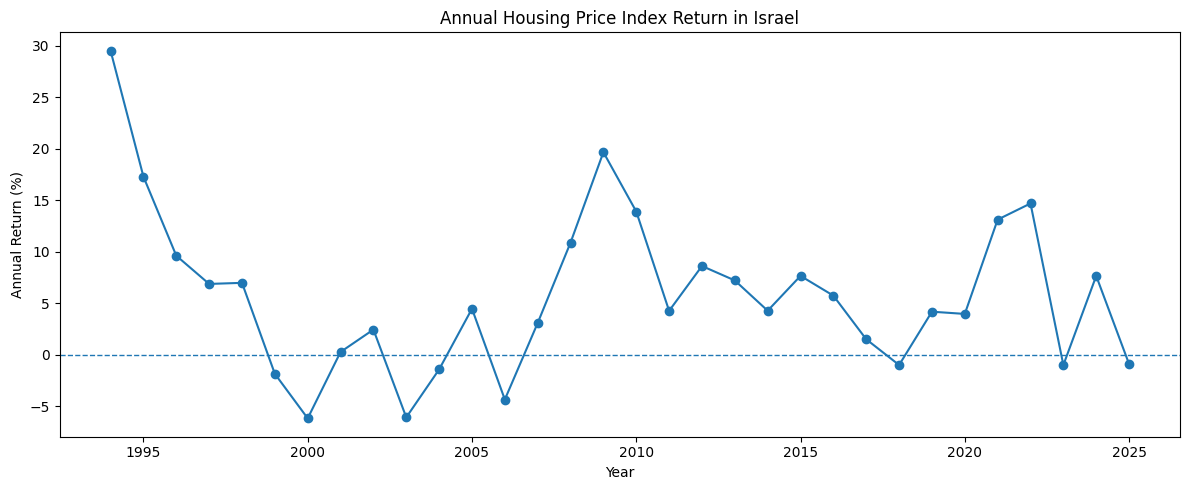

Arithmetic mean annual return: 5.78%
Standard deviation: 7.75%


In [ ]:
# Plot Annual Housing Price
plt.figure(figsize=(12, 5))
plt.plot(housing_table["year"], housing_table["annual_return_pct"], marker="o")
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Annual Housing Price Index Return in Israel")
plt.xlabel("Year")
plt.ylabel("Annual Return (%)")
plt.tight_layout()
plt.show()

# Calculate statistics (without modifying the table)
mean_return = housing_table["annual_return_pct"].mean()
std_return = housing_table["annual_return_pct"].std()

print(f"Arithmetic mean annual return: {mean_return:.2f}%")
print(f"Standard deviation: {std_return:.2f}%")


The average return and standard deviation are relatively low, indicating that housing is a stable asset, but with comparatively lower returns.

#### **sp500_Annual_Total_Returns_1926_2025**

A 100-year historical sample used to analyze long-term trends, major crises, peak periods, and long-term investment returns.

In [ ]:
# Data loading and cleaning
raw_sp500_yearly = pd.read_csv("/content/drive/MyDrive/data_science/final_project/sp500_annual_total_returns_1926_2025.csv",header=None)

# Keeps the two relevant columns
sp500_yearly = raw_sp500_yearly.iloc[:, :2].copy()

# Renames columns
sp500_yearly.columns = ["year", "annual_return_pct"]

# Converts columns to numeric
sp500_yearly = sp500_yearly.apply(pd.to_numeric, errors="coerce")

# Sorts years in ascending order
sp500_yearly = sp500_yearly.sort_values("year").reset_index(drop=True)

sp500_yearly.head()

,year,annual_return_pct
0,1926,11.62
1,1927,37.49
2,1928,43.61
3,1929,-8.42
4,1930,-24.90


In [ ]:
# Structure and integrity check
years = sp500_yearly["year"].astype(int)

print("Shape:", sp500_yearly.shape)
print("Years:", f"{years.min()}-{years.max()}")
print("Missing values:\n", sp500_yearly.isna().sum())
print("Duplicate years:", years.duplicated().sum())
print("Continuous years:", years.tolist() == list(range(years.min(), years.max() + 1)))

Shape: (100, 2)
Years: 1926-2025
Missing values:
 year                 0
annual_return_pct    0
dtype: int64
Duplicate years: 0
Continuous years: True


The dataset appears clean and structurally valid.

In [ ]:
# Extreme values, mean and std check
annual_values = sp500_yearly["annual_return_pct"].dropna()
print("5 lowest annual returns:", annual_values.nsmallest(5).tolist())
print("5 highest annual returns:", annual_values.nlargest(5).tolist())
print("Arithmetic mean annual return:", round(annual_values.mean(), 3))
print("Std annual return:", round(annual_values.std(), 3))

5 lowest annual returns: [-43.34, -37.0, -35.03, -26.47, -24.9]
5 highest annual returns: [53.99, 52.62, 47.67, 43.61, 43.36]
Arithmetic mean annual return: 12.345
Std annual return: 19.573


Extreme values reasonable and verified.

Arithmetic mean is reasonable. standard deviation is relatively high, suggesting high volatility.

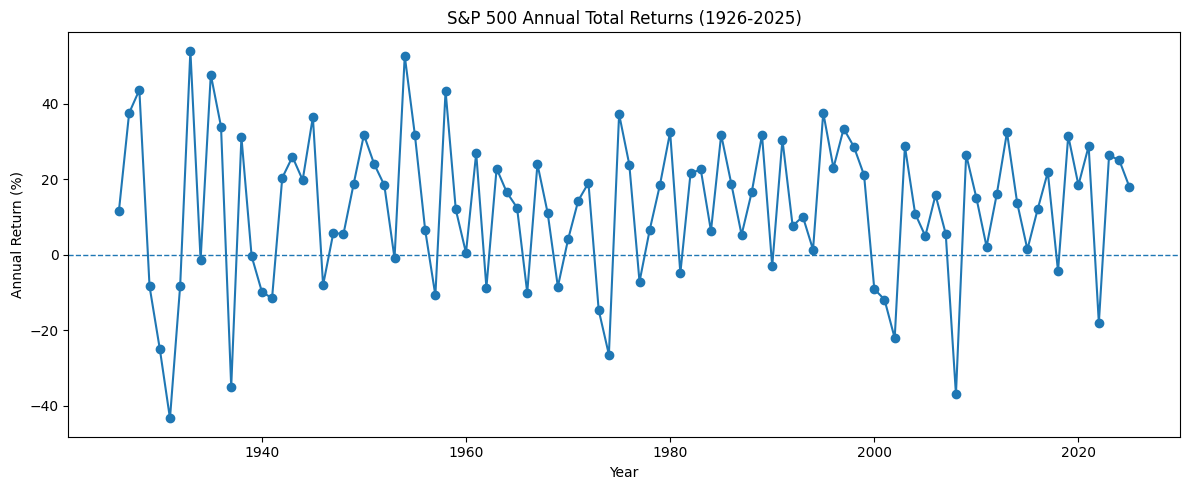

Arithmetic mean annual return: 12.345
Std annual return: 19.573


In [ ]:
# Plots annual S&P 500 returns over time
plt.figure(figsize=(12, 5))
plt.plot(sp500_yearly["year"], sp500_yearly["annual_return_pct"], marker="o")
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("S&P 500 Annual Total Returns (1926-2025)")
plt.xlabel("Year")
plt.ylabel("Annual Return (%)")
plt.tight_layout()
plt.show()

print("Arithmetic mean annual return:", round(annual_values.mean(), 3))
print("Std annual return:", round(annual_values.std(), 3))

The average return and standard deviation are relatively high, indicating that housing is a volatile asset, but with comparatively higher returns.

 #### **sp500_monthly_total_returns_1988_2025**



In [ ]:
# Data loading and cleaning
raw_sp500_monthly = pd.read_csv("/content/drive/MyDrive/data_science/final_project/sp500_monthly_total_returns_1988_2026.csv")

# Keeps the relevant columns and cleans the dataset
sp500_monthly_tr = raw_sp500_monthly.iloc[:, [0, 2, 1, 6]].copy()
sp500_monthly_tr.columns = ["date", "open", "price", "monthly_return_pct"]

# Converts the date column to datetime
sp500_monthly_tr["date"] = pd.to_datetime(sp500_monthly_tr["date"], errors="coerce")

# Converts price columns to numeric after removing commas
for col in ["open", "price"]:
    sp500_monthly_tr[col] = pd.to_numeric(
        sp500_monthly_tr[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Converts monthly return values from percent strings to numeric
sp500_monthly_tr["monthly_return_pct"] = pd.to_numeric(
    sp500_monthly_tr["monthly_return_pct"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

# Sorts the dataset chronologically
sp500_monthly_tr = sp500_monthly_tr.sort_values("date").reset_index(drop=True)

sp500_monthly_tr.head()

,date,open,price,monthly_return_pct
0,1988-07-01,276.86,277.49,-0.38
1,1988-08-01,277.76,268.07,-3.39
2,1988-09-01,264.85,279.49,4.26
3,1988-10-01,279.08,287.27,2.78
4,1988-11-01,287.51,283.18,-1.42


In [ ]:
# Structure and integrity check
dates = sp500_monthly_tr["date"]
expected_months = pd.date_range(dates.min(), dates.max(), freq="MS")

print("Date range:", f"{dates.min().strftime('%Y-%m')} to {dates.max().strftime('%Y-%m')}")
print("Missing values:\n", sp500_monthly_tr.isna().sum())
print("Duplicate dates:", dates.duplicated().sum())
print("Missing months:", len(expected_months.difference(dates)))

Date range: 1988-07 to 2026-03
Missing values:
 date                  0
open                  0
price                 0
monthly_return_pct    0
dtype: int64
Duplicate dates: 0
Missing months: 0


The dataset appears clean and structurally valid.

In [ ]:
# Checks if the monthly_return_pct was calculated correctly
sp500_monthly_tr["previous_price"] = sp500_monthly_tr["price"].shift(1)

# Calculates the return from the previous month's price
sp500_monthly_tr["calculated_return_pct"] = (
    (sp500_monthly_tr["price"] / sp500_monthly_tr["previous_price"] - 1) * 100
)
# Measures the gap between reported and recalculated returns
sp500_monthly_tr["difference"] = (
    sp500_monthly_tr["monthly_return_pct"] - sp500_monthly_tr["calculated_return_pct"]
)

# Checks whether the values match after rounding to 2 decimals
sp500_monthly_tr["match_2dp"] = (
    sp500_monthly_tr["monthly_return_pct"].round(2)
    == sp500_monthly_tr["calculated_return_pct"].round(2)
)

print("Mean absolute difference:", round(sp500_monthly_tr["difference"].abs().mean(), 6))
print("Max absolute difference:", round(sp500_monthly_tr["difference"].abs().max(), 6))
print("Match rate (%):", round(sp500_monthly_tr["match_2dp"].mean() * 100, 2))

sp500_monthly_tr.loc[
    ~sp500_monthly_tr["match_2dp"],
    ["date", "previous_price", "price", "monthly_return_pct", "calculated_return_pct", "difference"]
].head(10)

Mean absolute difference: 0.002461
Max absolute difference: 0.005004
Match rate (%): 99.56


,date,previous_price,price,monthly_return_pct,calculated_return_pct,difference
0,1988-07-01,NaN,277.49,-0.38,NaN,NaN
363,2018-10-01,5763.42,5369.49,-6.83,-6.835004,0.005004


Differences are negligible, the monthly return percentage appears accurate.

In [ ]:
 # Summarizes the monthly return series and checks extreme values
returns = sp500_monthly_tr["monthly_return_pct"]

print("5 lowest monthly returns:", returns.nsmallest(5).tolist())
print("5 highest monthly returns:", returns.nlargest(5).tolist())

print("Arithmetic Mean monthly return:", round(returns.mean(), 3))
print("Std monthly return:", round(returns.std(), 3))

5 lowest monthly returns: [-16.8, -14.46, -12.35, -10.87, -10.65]
5 highest monthly returns: [12.82, 11.44, 10.95, 10.93, 9.78]
Arithmetic Mean monthly return: 0.969
Std monthly return: 4.216


Extreme values look reasonable and verified.

The arithmetic mean is positive, and the relatively high standard deviation suggests high volatility.

## **2. Best, worst, and average outcomes**

**All possible rolling windows** means checking every possible period of the same length in the dataset,

**Simple example:**

For a 10-year horizon in the S&P 500 :

- 1926-1936  
- 1927-1937  
- 1928-1938  
- ...  
- 2016-2026  


**CAGR (Compound Annual Growth Rate)** is the effective annual growth rate that takes into account compound growth over time.
$\
CAGR = \left(\frac{Final\ Value}{Initial\ Value}\right)^{\frac{1}{n}} - 1
\$

<br>

**Simple example of why it is needed:**

- Year 0 = \$100
- Year 1 = \$50 (-50\%)
- Year 2 = \$75 (+50\%)

<br>

**Arithmetic average return:** $\frac{-50\% + 50\%}{2} = 0\%$

**But the actual total return is:** $\frac{75}{100} - 1 = -25\%$

<br>

$CAGR = \left(\frac{75}{100}\right)^{\frac{1}{2}} - 1 \approx -13.4\%$

**CAGR = -13.4\%** means that the investment shrank at an effective annual rate of about **13.4\% per year** over the two-year period.

$100 \cdot (1 - 0.134)^2 \approx 75$

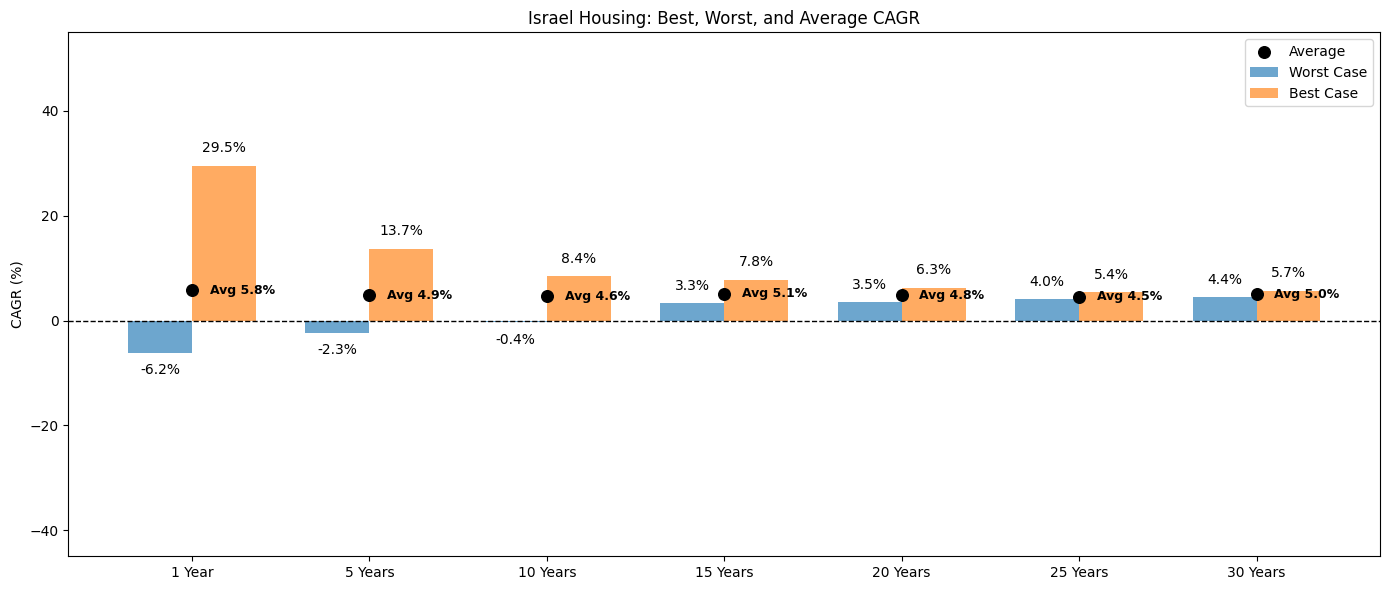

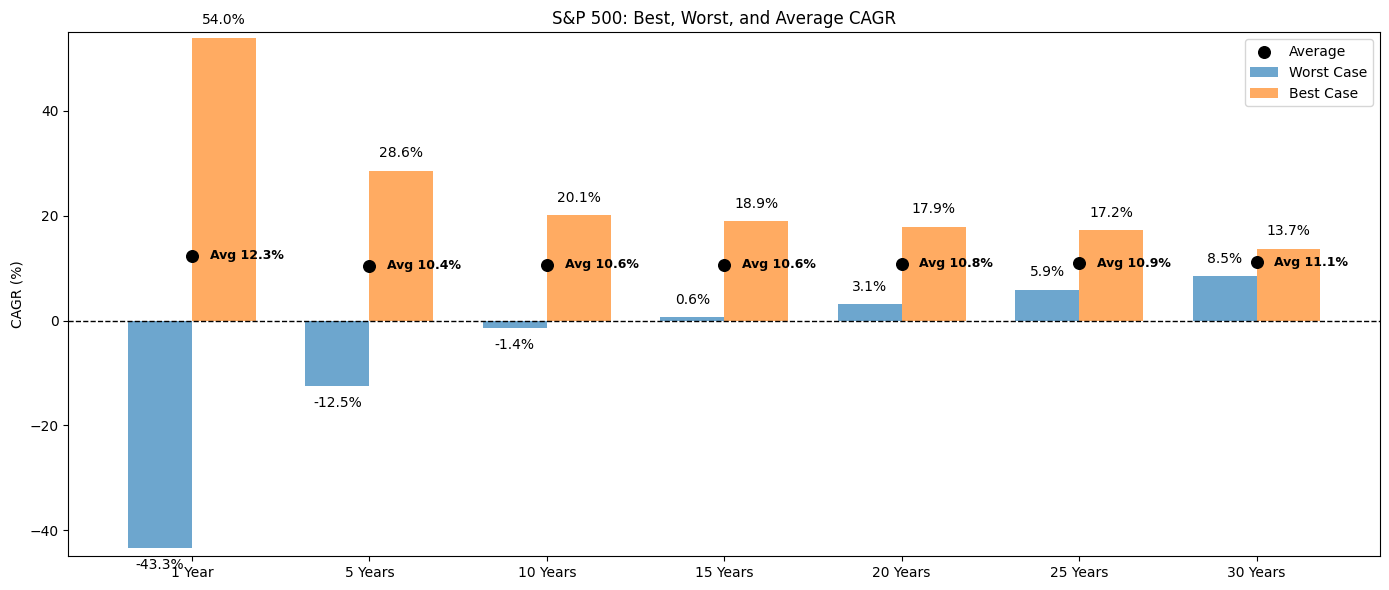

In [ ]:
# List of rolling window periods
periods = [1, 5, 10, 15, 20, 25, 30]

# Efficiently calculates min, max, and average for BOTH CAGR and Cumulative Growth
def get_rolling_summary(df, periods):
    growth = 1 + df["annual_return_pct"].dropna() / 100
    summary = []

    for y in periods:
        if len(growth) >= y:
            cum_growth = (growth.rolling(y).apply(np.prod) - 1) * 100
            cagr = ((cum_growth / 100 + 1) ** (1 / y) - 1) * 100

            summary.append({
                "period_years": y,
                "cagr_worst": cagr.min(), "cagr_best": cagr.max(), "cagr_average": cagr.mean(),
                "cum_worst": cum_growth.min(), "cum_best": cum_growth.max(), "cum_average": cum_growth.mean()
            })

    return pd.DataFrame(summary)

# General plotting function for any metric (CAGR or Cumulative)
def plot_summary(df, title, ylabel, col_prefix, ymin, ymax, decimals=1):
    x = np.arange(len(df))
    plt.figure(figsize=(14, 6))

    worst = df[f"{col_prefix}_worst"]
    best = df[f"{col_prefix}_best"]
    avg = df[f"{col_prefix}_average"]

    plt.bar(x - 0.18, worst, width=0.36, alpha=0.65, label="Worst Case")
    plt.bar(x + 0.18, best, width=0.36, alpha=0.65, label="Best Case")
    plt.scatter(x, avg, s=70, color="black", label="Average", zorder=3)

    # Dynamic offset and string formatting
    offset = (ymax - ymin) * 0.02
    fmt = f",.{decimals}f"

    for i in range(len(df)):
        plt.text(i - 0.18, worst.iloc[i] + (offset if worst.iloc[i] >= 0 else -offset), f"{worst.iloc[i]:{fmt}}%", ha="center", va="bottom" if worst.iloc[i] >= 0 else "top")
        plt.text(i + 0.18, best.iloc[i] + offset, f"{best.iloc[i]:{fmt}}%", ha="center", va="bottom")
        plt.text(i + 0.1, avg.iloc[i], f"Avg {avg.iloc[i]:{fmt}}%", va="center", fontsize=9, fontweight="bold")

    plt.axhline(0, linestyle="--", linewidth=1, color="black")
    plt.ylim(ymin, ymax)
    plt.xticks(x, [f"{int(y)} Years" if y > 1 else "1 Year" for y in df["period_years"]])
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


# Process data once for all comparisons
housing_summary = get_rolling_summary(housing_table, periods)
sp500_summary = get_rolling_summary(sp500_yearly, periods)

# Plot CAGR comparison
c_min = min(housing_summary["cagr_worst"].min(), sp500_summary["cagr_worst"].min())
c_max = max(housing_summary["cagr_best"].max(), sp500_summary["cagr_best"].max())
y_min_cagr, y_max_cagr = np.floor(c_min / 5) * 5, np.ceil(c_max / 5) * 5

plot_summary(housing_summary, "Israel Housing: Best, Worst, and Average CAGR", "CAGR (%)", "cagr", y_min_cagr, y_max_cagr, decimals=1)
plot_summary(sp500_summary, "S&P 500: Best, Worst, and Average CAGR", "CAGR (%)", "cagr", y_min_cagr, y_max_cagr, decimals=1)

It can be seen that investing in housing is less risky in the short term, but less profitable in the long term. The average return is much higher in the S&P 500, but this comes with a wider range of outcomes.

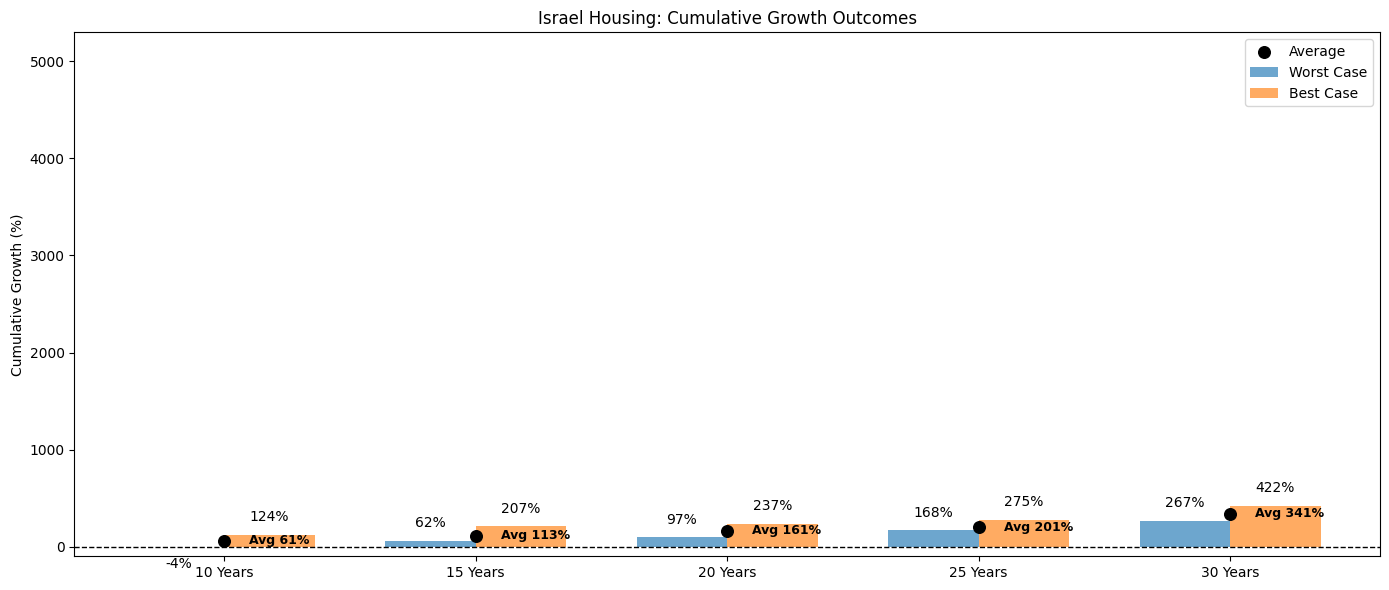

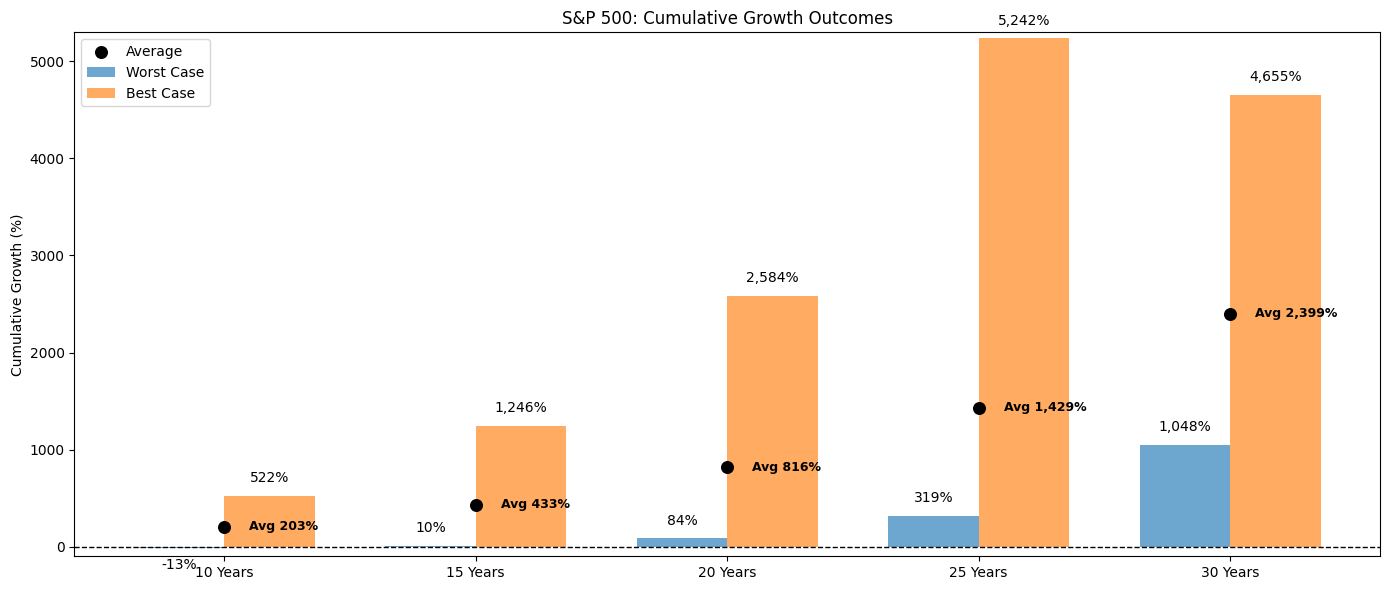

In [ ]:
# Keeps only the long periods for this comparison
growth_periods = [10, 15, 20, 25, 30]

housing_growth_plot = housing_summary[housing_summary["period_years"].isin(growth_periods)].reset_index(drop=True)
sp500_growth_plot = sp500_summary[sp500_summary["period_years"].isin(growth_periods)].reset_index(drop=True)

# Find global min and max for identical Y-axes (rounding to nearest 100)
g_min = min(housing_growth_plot["cum_worst"].min(), sp500_growth_plot["cum_worst"].min())
g_max = max(housing_growth_plot["cum_best"].max(), sp500_growth_plot["cum_best"].max())
y_min, y_max = np.floor(g_min / 100) * 100, np.ceil(g_max / 100) * 100

# Plot Cumulative Growth using the shared function (decimals=0 for large numbers)
plot_summary(housing_growth_plot, "Israel Housing: Cumulative Growth Outcomes", "Cumulative Growth (%)", "cum", y_min, y_max, decimals=0)
plot_summary(sp500_growth_plot, "S&P 500: Cumulative Growth Outcomes", "Cumulative Growth (%)", "cum", y_min, y_max, decimals=0)

Already over 25 years, even the worst-case S&P 500 outcome is more profitable than best case return from residential housing.

This graph shows how large the gap becomes the over long term under exponential growth, highlighting the power of compound interest.

## **3. Long-Term Performance and Recovery Analysis**


Average annual compounded return (CAGR): 10.49%
Summary of Major S&P 500 Crises (Drawdown > 15%):


,Peak Year,Trough Year,Recovery Year,Drawdown (%),Years to Bottom,Years to Recovery,Peak Value ($),Trough Value ($)
0,1928,1932,1936,-64.2,4,8,2.20,0.79
1,1936,1937,1943,-35.0,1,7,2.37,1.54
2,1972,1974,1976,-37.2,2,4,84.96,53.31
3,1999,2002,2006,-37.6,3,7,2847.81,1776.80
4,2007,2008,2012,-37.0,1,5,3248.64,2046.64
5,2021,2022,2023,-18.1,1,2,14066.89,11519.38


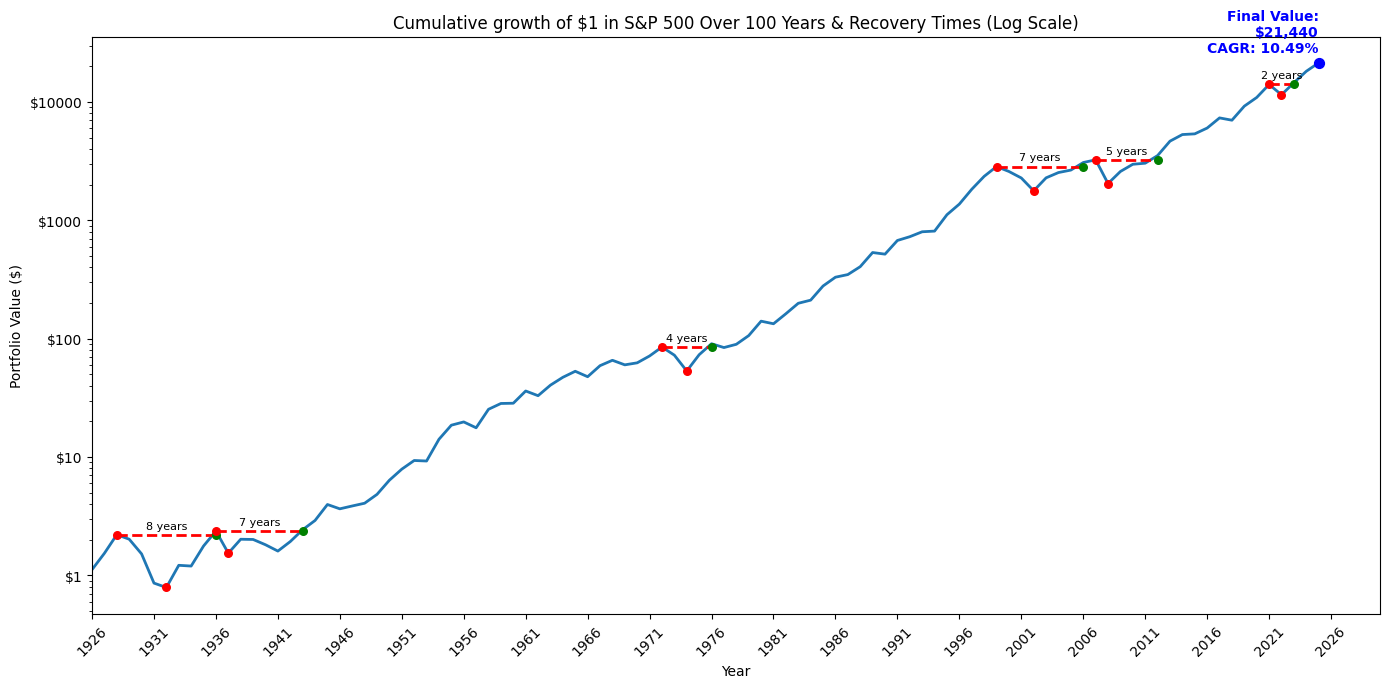

In [ ]:
# Calculates cumulative wealth from $1
df = sp500_yearly[["year", "annual_return_pct"]].dropna().sort_values("year").reset_index(drop=True)
df["wealth"] = (1 + df["annual_return_pct"] / 100).cumprod()

# Calculates average annual compounded return (CAGR)
num_years = len(df)
final_val = df["wealth"].iloc[-1]
cagr = (final_val ** (1 / num_years) - 1) * 100

print(f"Average annual compounded return (CAGR): {cagr:.2f}%")

df["running_max"] = df["wealth"].cummax()
df["drawdown"] = df["wealth"] / df["running_max"] - 1

# Identifies peaks to track drawdowns
df["is_peak"] = df["wealth"] == df["running_max"]
df["peak_year"] = df["year"].where(df["is_peak"]).ffill()

crises = []

# Finds major crashes (>15%) and calculates recovery
for peak_yr, group in df.groupby("peak_year"):
    if len(group) > 1 and group["drawdown"].min() <= -0.15:
        trough_idx = group["wealth"].idxmin()
        trough_yr = df.loc[trough_idx, "year"]
        peak_val = group["running_max"].iloc[0]

        recovery_slice = df[(df["year"] > trough_yr) & (df["wealth"] >= peak_val)]
        recovery_yr = recovery_slice["year"].iloc[0] if not recovery_slice.empty else None

        if recovery_yr is not None:
            crises.append({
                "Peak Year": int(peak_yr),
                "Trough Year": int(trough_yr),
                "Recovery Year": int(recovery_yr),
                "Drawdown (%)": round(group["drawdown"].min() * 100, 1),
                "Years to Bottom": int(trough_yr - peak_yr),
                "Years to Recovery": int(recovery_yr - peak_yr),
                "Peak Value ($)": round(peak_val, 2),
                "Trough Value ($)": round(df.loc[trough_idx, "wealth"], 2)
            })

major_crises = pd.DataFrame(crises).sort_values("Peak Year").reset_index(drop=True)

print("Summary of Major S&P 500 Crises (Drawdown > 15%):")
display(major_crises)

# Plots cumulative growth and recovery times
plt.figure(figsize=(14, 7))
plt.plot(df["year"], df["wealth"], linewidth=2)

for _, row in major_crises.iterrows():
    plt.plot([row["Peak Year"], row["Recovery Year"]], [row["Peak Value ($)"], row["Peak Value ($)"]], "r--", lw=2)
    plt.scatter([row["Peak Year"], row["Trough Year"]], [row["Peak Value ($)"], row["Trough Value ($)"]], color="red", s=30, zorder=5)
    plt.scatter(row["Recovery Year"], row["Peak Value ($)"], color="green", s=30, zorder=5)

    mid_x = (row["Peak Year"] + row["Recovery Year"]) / 2
    plt.text(mid_x, row["Peak Value ($)"] * 1.08, f"{int(row['Years to Recovery'])} years", ha="center", va="bottom", fontsize=8)

# Adds final value marker and CAGR text
final_year = df["year"].iloc[-1]
plt.scatter(final_year, final_val, color="blue", s=50, zorder=5)
plt.text(
    final_year,
    final_val * 1.15,
    f"Final Value:\n${final_val:,.0f}\nCAGR: {cagr:.2f}%",
    ha="right",
    va="bottom",
    fontsize=10,
    fontweight="bold",
    color="blue"
)

# Formats axes to log scale
plt.yscale("log")
plt.xlim(left=1926)

formatter = FuncFormatter(lambda y, _: f'${y:g}')
plt.gca().yaxis.set_major_formatter(formatter)

plt.xlabel("Year")
plt.ylabel("Portfolio Value ($)")
plt.title("Cumulative growth of $1 in S&P 500 Over 100 Years & Recovery Times (Log Scale)")
plt.xticks(np.arange(1926, df["year"].max() + 5, 5), rotation=45)
plt.tight_layout()
plt.show()

Explanation of the graph

- **Log Scale**: To make exponential growth appear linear, which helps visualize the actual steady rate of return over time.

- **Demonstrates the incredible power of exponential growth**: A \$1 investment grew to over \$21,440 in 100 years with average return of 10.49%.

Conclusions from the graph

- **Mental resilience to crashes**: While the S&P 500 is highly rewarding in the long run, every investor must honestly ask themselves whether they can handle the stress of waiting years to recover from a crash, e.g., around 15 years after 1929 or around 12 years after 2000.

- **Low chance of worst-case timing:** Chances of investing at the absolute worst possible moment, right before a major crash, are relatively low.





Average annual compounded return (CAGR): 5.51%
Summary of Israel Housing Crises (Drawdown > 5%):


,Peak Year,Trough Year,Recovery Year,Drawdown (%),Years to Bottom,Years to Recovery,Peak Value ($),Trough Value ($)
0,1998,2006,2008,-12.5,8,10,1.9,1.66


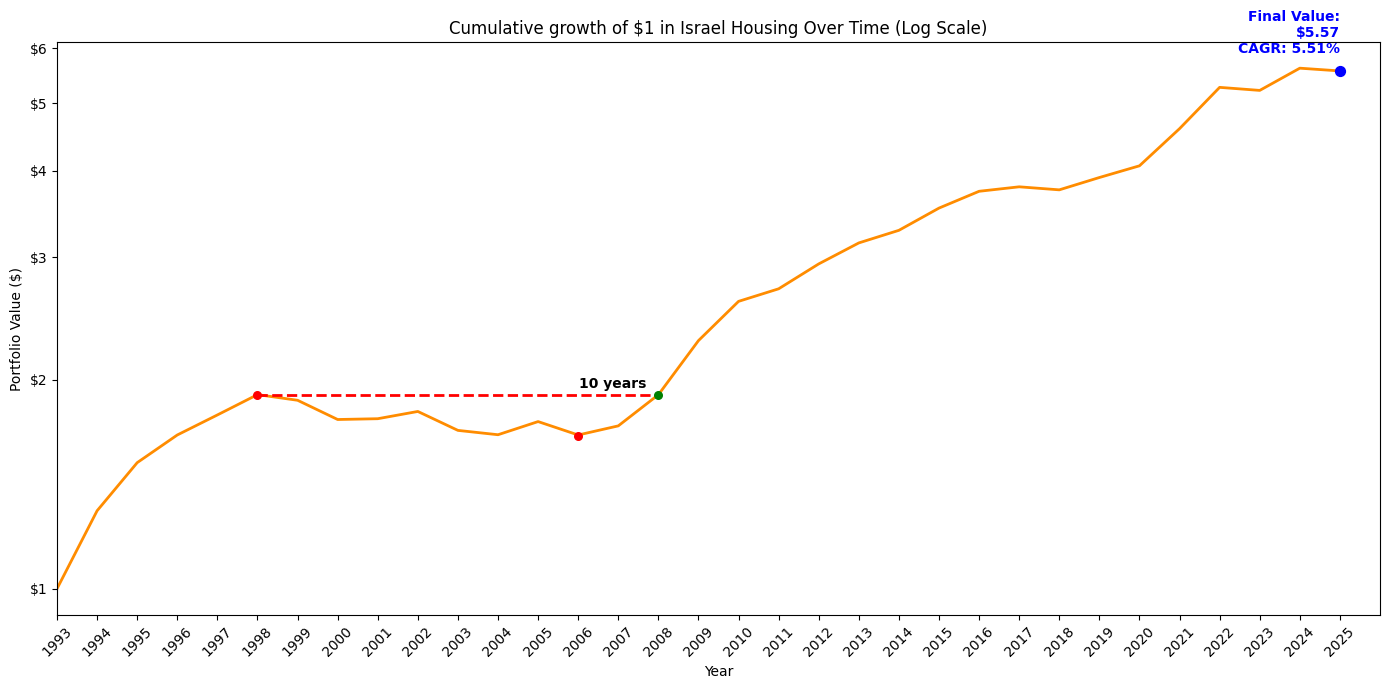

In [ ]:
# Calculates cumulative wealth from $1
df_housing = housing_table[["year", "annual_return_pct"]].dropna().sort_values("year").reset_index(drop=True)
df_housing["wealth"] = (1 + df_housing["annual_return_pct"] / 100).cumprod()

# Calculates average annual compounded return (CAGR)
num_years_h = len(df_housing)
final_val_h = df_housing["wealth"].iloc[-1]
cagr_h = (final_val_h ** (1 / num_years_h) - 1) * 100

print(f"Average annual compounded return (CAGR): {cagr_h:.2f}%")

# Adds year 0 as starting point for visualization only
start_year = df_housing["year"].min() - 1
start_row = pd.DataFrame({"year": [start_year], "annual_return_pct": [0.0], "wealth": [1.0]})
df_housing = pd.concat([start_row, df_housing]).reset_index(drop=True)

df_housing["running_max"] = df_housing["wealth"].cummax()
df_housing["drawdown"] = df_housing["wealth"] / df_housing["running_max"] - 1

# Identifies peaks to track drawdowns
df_housing["is_peak"] = df_housing["wealth"] == df_housing["running_max"]
df_housing["peak_year"] = df_housing["year"].where(df_housing["is_peak"]).ffill()

crises_housing = []

# Finds major crashes (>5%) and calculates recovery (1% tolerance)
threshold = -0.05
for peak_yr, group in df_housing.groupby("peak_year"):
    if len(group) > 1 and group["drawdown"].min() <= threshold:
        trough_idx = group["wealth"].idxmin()
        trough_yr = df_housing.loc[trough_idx, "year"]
        peak_val = group["running_max"].iloc[0]

        recovery_slice = df_housing[
            (df_housing["year"] > trough_yr) &
            (df_housing["wealth"] >= peak_val * 0.99)
        ]
        recovery_yr = recovery_slice["year"].iloc[0] if not recovery_slice.empty else None

        if recovery_yr is not None:
            crises_housing.append({
                "Peak Year": int(peak_yr),
                "Trough Year": int(trough_yr),
                "Recovery Year": int(recovery_yr),
                "Drawdown (%)": round(group["drawdown"].min() * 100, 1),
                "Years to Bottom": int(trough_yr - peak_yr),
                "Years to Recovery": int(recovery_yr - peak_yr),
                "Peak Value ($)": round(peak_val, 2),
                "Trough Value ($)": round(df_housing.loc[trough_idx, "wealth"], 2)
            })

major_crises_housing = pd.DataFrame(crises_housing)

if not major_crises_housing.empty:
    major_crises_housing = major_crises_housing.sort_values("Peak Year").reset_index(drop=True)
    print("Summary of Israel Housing Crises (Drawdown > 5%):")
    display(major_crises_housing)

# Plots cumulative growth and recovery times
plt.figure(figsize=(14, 7))
plt.plot(df_housing["year"], df_housing["wealth"], linewidth=2, color="darkorange")

if not major_crises_housing.empty:
    for _, row in major_crises_housing.iterrows():
        plt.plot(
            [row["Peak Year"], row["Recovery Year"]],
            [row["Peak Value ($)"], row["Peak Value ($)"]],
            "r--",
            lw=2
        )
        plt.scatter(
            [row["Peak Year"], row["Trough Year"]],
            [row["Peak Value ($)"], row["Trough Value ($)"]],
            color="red",
            s=30,
            zorder=5
        )
        plt.scatter(row["Recovery Year"], row["Peak Value ($)"], color="green", s=30, zorder=5)

        text_x = row["Recovery Year"] - 0.3
        text_y = row["Peak Value ($)"] * 1.015
        plt.text(
            text_x,
            text_y,
            f"{int(row['Years to Recovery'])} years",
            ha="right",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

# Adds final value marker and CAGR text
final_year_h = df_housing["year"].iloc[-1]
plt.scatter(final_year_h, final_val_h, color="blue", s=50, zorder=5)
plt.text(
    final_year_h,
    final_val_h * 1.05,
    f"Final Value:\n${final_val_h:,.2f}\nCAGR: {cagr_h:.2f}%",
    ha="right",
    va="bottom",
    fontsize=10,
    fontweight="bold",
    color="blue"
)

min_year = int(df_housing["year"].min())
max_year = int(df_housing["year"].max())
plt.xlim(left=min_year, right=max_year + 1)

# Formats axes to match S&P 500 chart
plt.yscale("log")
plt.yticks(np.arange(1, int(final_val_h) + 2, 1))

formatter = FuncFormatter(lambda y, _: f"${y:g}")
plt.gca().yaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_minor_formatter(plt.NullFormatter())

plt.xlabel("Year")
plt.ylabel("Portfolio Value ($)")
plt.title("Cumulative growth of $1 in Israel Housing Over Time (Log Scale)")
plt.xticks(np.arange(min_year, max_year + 1, 1), rotation=45)

plt.tight_layout()
plt.show()

Explanation of the graph

- **Log Scale:** This scale makes exponential growth appear linear, which helps visualize the actual steady rate of return over time.

- **Demonstrates slow stable growth:** A \$1 investment in Israel housing grew to about \$5.57, but this result reflects only about 32 years of data, compared to 100 years in the S&P 500 graph.

Conclusions from the graph
- **Worst period relatively calm:** The decline in the Israeli housing index **was fairly small, reaching only about a 12% decline** at its lowest point. Even though the recovery period lasted around 10 years, it still represents a relatively low-risk investment that lets investors sleep well at night.

- **Final value is \$5.57:** With an average annual return of 5.51%, which is relatively low compared to the S&P 500. If we had invested in the index and used an average annual return of 10.49%, we would have reached a final value of $24.34, demonstrating how much more profitable a stock market index is on average over the long run.

## **4. Volatility Analysis**

The standard deviation we found was at the "Exploratory Data Analysis" stage:

- S&P 500 Std annual: 19.57%
- Housing Std annual: 7.75%

---
- Housing Std monthly: 1.035%
- S&P 500 Std monthly: 4.216%

The S&P 500 has significantly higher volatility:
  - About **2.5× higher annual volatility**
  - About **4× higher monthly volatility**

At the "Exploratory Data Analysis" stage, we examined annual return graphs, but now we will dive deeper into monthly changes to better understand how volatility really looks.

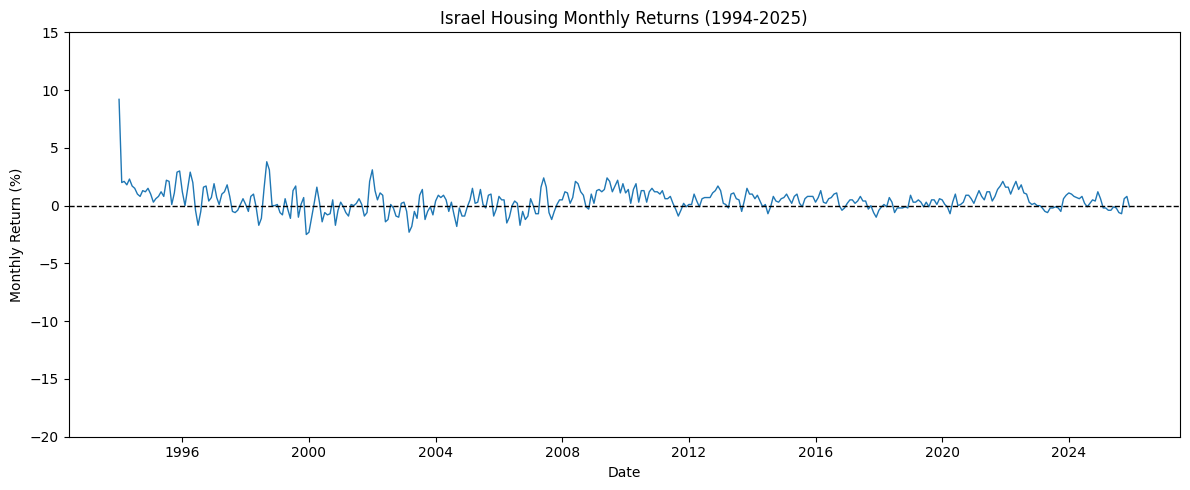

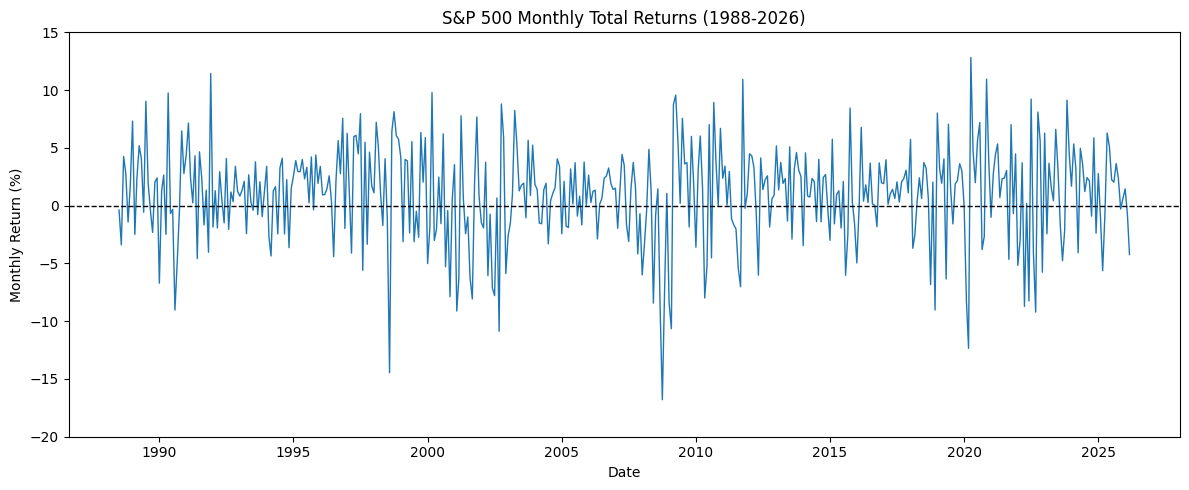

In [ ]:
# 1. Recreate 'housing_monthly' using the existing 'housing_table' and 'months'
housing_monthly = housing_table.melt(
    id_vars="year",
    value_vars=months,
    var_name="month",
    value_name="monthly_return_pct"
)

housing_monthly["date"] = pd.to_datetime({
    "year": housing_monthly["year"],
    "month": housing_monthly["month"].map(dict(zip(months, range(1, 13)))),
    "day": 1
})

housing_monthly = housing_monthly.sort_values("date").dropna().reset_index(drop=True)


# 2. Plot both charts with a shared Y-axis
# Find the global min and max to create a shared Y-axis scale
global_min = min(housing_monthly["monthly_return_pct"].min(), sp500_monthly_tr["monthly_return_pct"].min())
global_max = max(housing_monthly["monthly_return_pct"].max(), sp500_monthly_tr["monthly_return_pct"].max())

# Round to nearest multiple of 5 for clean ticks (e.g., -20, -15, ... 5, 10, 15)
y_min = np.floor(global_min / 5) * 5
y_max = np.ceil(global_max / 5) * 5
y_ticks = np.arange(y_min, y_max + 5, 5)

# Plot Israel Housing Monthly Returns
plt.figure(figsize=(12, 5))
plt.plot(housing_monthly["date"], housing_monthly["monthly_return_pct"], linewidth=1)
plt.axhline(0, linestyle="--", linewidth=1, color="black")

# Apply the shared scale and ticks
plt.ylim(y_min, y_max)
plt.yticks(y_ticks)

plt.title("Israel Housing Monthly Returns (1994-2025)")
plt.xlabel("Date")
plt.ylabel("Monthly Return (%)")
plt.tight_layout()
plt.show()

# Plot S&P 500 Monthly Total Returns
plt.figure(figsize=(12, 5))
plt.plot(sp500_monthly_tr["date"], sp500_monthly_tr["monthly_return_pct"], linewidth=1)
plt.axhline(0, linestyle="--", linewidth=1, color="black")

# Apply the exact same scale and ticks
plt.ylim(y_min, y_max)
plt.yticks(y_ticks)

plt.title("S&P 500 Monthly Total Returns (1988-2026)")
plt.xlabel("Date")
plt.ylabel("Monthly Return (%)")
plt.tight_layout()
plt.show()

- Residential housing appears relatively smooth and moderate, which makes it easier to sleep well at night.

- S&P 500 behaves much more like a roller coaster, with sharper swings and greater uncertainty, but   historically delivered higher long-term returns.

- Ultimately, the key question is whether an investor is willing to accept higher risk and volatility in exchange for higher returns.

## **5. Mortgage Advantage Analysis**



Mortgage interest rate depends mainly on:

- overall interest rate environment
- financing percentage
- borrower risk profile, including income, credit score, and banking behavior
- loan term
- mortgage track, such as fixed or variable, indexed or non-indexed
- bargaining power with the bank
- Additional costs - insurance, fees, advisor costs.

The cost of a mortgage is usually in the range of 2% to 8%, depending on the conditions, and in 2026 the Interest is around 4.8% to 5% according to the Bank of Israel.

In this research, residential housing generated an average annual return of about 5% over 30-year periods.

**So when does a mortgage actually improve the return?**

Only **when the return on the property is higher than the mortgage** interest rate.


**Demonstration** : We use a heatmap table to show the Extra Profit gained or lost by using a mortgage.

- The percentages in the table represent the extra profit compared to buying with 100% equity (no loan).

- Assuming 75% mortgage and 25% investor equity.
- Extra Profit = 3 × (House Profit - Mortgage Cost)



For example, if:

**House Return = 5%  
Mortgage Cost = 4%**

Then:

**Extra Profit = 3 × (5% - 4%) = 3%**



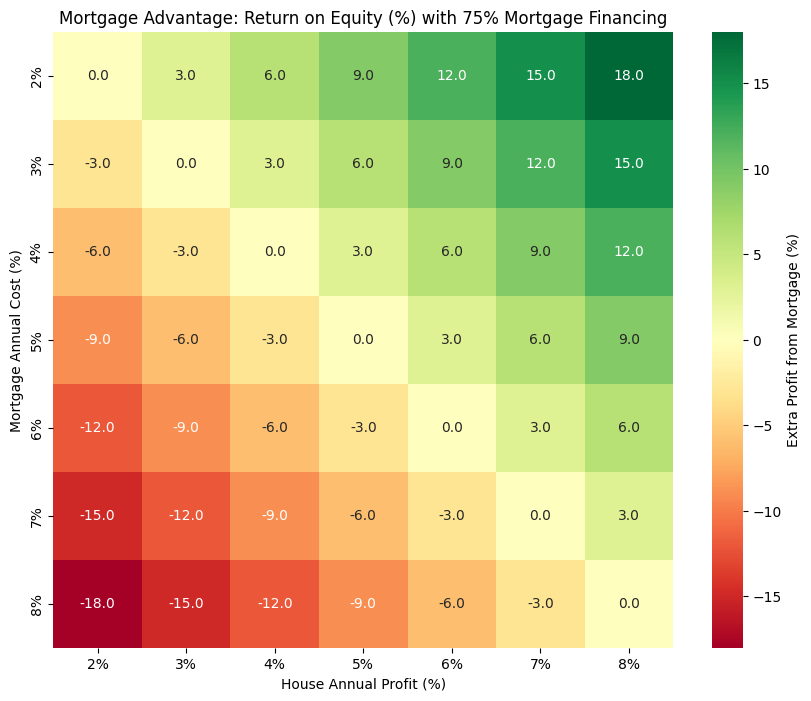

In [ ]:
# Visualize the "Extra Profit" gained or lost by using a mortgage.
def plot_leverage_advantage_heatmap():
    loan_share = 0.75
    my_money_share = 0.25
    rates = np.arange(2, 9)

    # Calculation for Return on Equity
    # house_profit[None, :] is X axis, loan_cost[:, None] is Y axis
    roe = (rates[None, :] - loan_share * rates[:, None]) / my_money_share

    # Calculation for "Leverage Advantage": How much EXTRA you made vs. not taking a loan
    # On the diagonal (where House Profit = Loan Cost), this will always be 0.
    leverage_advantage = roe - rates[None, :]

    df = pd.DataFrame(
        leverage_advantage,
        index=[f"{r}%" for r in rates],
        columns=[f"{r}%" for r in rates]
    )

    plt.figure(figsize=(10, 8))

    # Use center=0 so that 0 (no advantage) is always yellow.
    # Positive values = Green (Loan helped), Negative values = Red (Loan hurt).
    sns.heatmap(df, annot=True, fmt=".1f", cmap="RdYlGn", center=0,
                cbar_kws={'label': 'Extra Profit from Mortgage (%)'})

    plt.title("Mortgage Advantage: Return on Equity (%) with 75% Mortgage Financing")
    plt.xlabel("House Annual Profit (%)")
    plt.ylabel("Mortgage Annual Cost (%)")
    plt.show()

plot_leverage_advantage_heatmap()

In 2026, looking at the last 30 years of the housing market, it generated an average annual return of about 5%, while the current mortgage cost is also around 5%.

This means **there is almost no advantage to using a mortgage under average conditions at this time**.

However, during periods of lower interest rates, mortgage financing can improve return on equity when the property generates a higher return than the mortgage cost. For example, in 2021, the average mortgage interest rate was around 2.3%.

**Additional checks with 50% and 25% mortgage financing showed the same overall pattern, but with a smaller leverage effect.**

In the 50% financing case, the extra profit values are 1/3 of those in the 75% financing case, while in the 25% financing case they are 1/9 of those in the 75% financing case.

For clarity, only the 75% financing case is presented here, as it illustrates the impact of mortgage leverage most clearly.

## **6. Final Simulation**

In [ ]:
# Setup basic parameters for the simulation
home_value = 1000000
mortgage_rate = 0.048
home_appreciation = 0.05
sp500_return = 0.111
years = 30
months = years * 12

# Calculate mortgage details
down_payment = home_value * 0.25
loan_amount = home_value * 0.75
monthly_interest = mortgage_rate / 12

# Calculate fixed monthly mortgage payment
mortgage_payment = loan_amount * (monthly_interest * (1 + monthly_interest)**months) / ((1 + monthly_interest)**months - 1)

# Scenario 1: Buying a House
future_home_value = home_value * ((1 + home_appreciation) ** years)
total_mortgage_paid = mortgage_payment * months
total_buyer_cost = down_payment + total_mortgage_paid
buyer_net_profit = future_home_value - total_buyer_cost

# Scenario 2: Renting and Investing in S&P 500
investment_balance = down_payment
monthly_sp500_return = (1 + sp500_return) ** (1/12) - 1
current_monthly_rent = (home_value * 0.03) / 12

total_rent_paid = 0
total_extra_invested = 0

# Run the 30-year simulation month by month
for month in range(1, months + 1):
    total_rent_paid += current_monthly_rent

    # Calculate difference between mortgage and rent
    monthly_investment = mortgage_payment - current_monthly_rent

    # Track extra money invested (only if mortgage > rent)
    if monthly_investment > 0:
        total_extra_invested += monthly_investment

    # Update portfolio balance
    investment_balance = investment_balance * (1 + monthly_sp500_return) + monthly_investment

    # Increase rent by 3% every year to simulate inflation
    if month % 12 == 0:
        current_monthly_rent *= 1.03

# Calculate renter net profit
total_renter_cost = down_payment + total_extra_invested + total_rent_paid
renter_net_profit = investment_balance - total_renter_cost

# Calculate the final profit gap
profit_gap = renter_net_profit - buyer_net_profit

# --- Print Results with Perfect Alignment ---
print("--- 30-Year Simulation: Detailed Breakdown ---\n")

# Use a fixed width of 42 characters for the labels to align all values perfectly
w = 42

print("[ Assumed Rates ]")
print(f"{'Mortgage Interest Rate (2026/02 Avg):':<{w}} {mortgage_rate * 100:.1f}%")
print(f"{'Annual Home Appreciation (30-Year Avg):':<{w}} {home_appreciation * 100:.1f}%")
print(f"{'Annual S&P 500 Return (30-Year Avg):':<{w}} {sp500_return * 100:.1f}%\n")

print("[ Buyer Scenario ]")
print(f"{'Initial Home Value:':<{w}} ${home_value:,.2f}")
print(f"{'Down Payment (25%):':<{w}} ${down_payment:,.2f}")
print(f"{'Monthly Mortgage Payment:':<{w}} ${mortgage_payment:,.2f}")
print(f"{'Total Mortgage Paid (30 Yrs):':<{w}} ${total_mortgage_paid:,.2f}")
print(f"{'Total Out-of-Pocket Cost:':<{w}} ${total_buyer_cost:,.2f}")
print(f"{'Final Home Value:':<{w}} ${future_home_value:,.2f}")
print(f"{'Net Profit (Value - Cost):':<{w}} ${buyer_net_profit:,.2f}\n")

print("[ Renter Scenario ]")
print(f"{'Initial Investment:':<{w}} ${down_payment:,.2f}")
print(f"{'Total Rent Paid (30 Yrs):':<{w}} ${total_rent_paid:,.2f}")
print(f"{'Total Extra Invested:':<{w}} ${total_extra_invested:,.2f}")
print(f"{'Total Out-of-Pocket Cost:':<{w}} ${total_renter_cost:,.2f}")
print(f"{'Final Stock Portfolio Value:':<{w}} ${investment_balance:,.2f}")
print(f"{'Net Profit (Value - Cost):':<{w}} ${renter_net_profit:,.2f}\n")

# Final summary of the gap
print("=" * 60)
print(f"{'TOTAL NET PROFIT GAP (Renter vs Buyer):':<{w}} ${profit_gap:,.2f}")
print("=" * 60)

--- 30-Year Simulation: Detailed Breakdown ---

[ Assumed Rates ]
Mortgage Interest Rate (2026/02 Avg):      4.8%
Annual Home Appreciation (30-Year Avg):    5.0%
Annual S&P 500 Return (30-Year Avg):       11.1%

[ Buyer Scenario ]
Initial Home Value:                        $1,000,000.00
Down Payment (25%):                        $250,000.00
Monthly Mortgage Payment:                  $3,934.99
Total Mortgage Paid (30 Yrs):              $1,416,596.46
Total Out-of-Pocket Cost:                  $1,666,596.46
Final Home Value:                          $4,321,942.38
Net Profit (Value - Cost):                 $2,655,345.92

[ Renter Scenario ]
Initial Investment:                        $250,000.00
Total Rent Paid (30 Yrs):                  $1,427,262.47
Total Extra Invested:                      $150,811.67
Total Out-of-Pocket Cost:                  $1,828,074.14
Final Stock Portfolio Value:               $7,735,958.46
Net Profit (Value - Cost):                 $5,907,884.32

TOTAL NET PROFIT

### Buyer Scenario (Buying a House)

- **Initial Home Value ($1,000,000.00):**  
  The starting price of the house.

- **Down Payment ($250,000.00):**  
  The initial cash paid (25% of the home's price).

- **Monthly Mortgage Payment ($3,934.99):**  
  The fixed monthly payment to the bank.

- **Total Mortgage Paid ($1,416,596.46):**  
  The total amount paid for the mortgage (principal + interest) over 30 years.

- **Total Out-of-Pocket Cost ($1,666,596.46):**  
  Total cash spent by the buyer over the years (Down payment + Total mortgage payments).

- **Final Home Value ($4,321,942.38):**  
  The value of the house after 30 years (assuming a 5% average annual appreciation).

- **Net Profit ($2,655,345.92):**  
  The buyer's pure profit (Final home value − Total out-of-pocket cost).

---

### Renter Scenario (Renting & Investing in S&P 500)

- **Initial Investment ($250,000.00):**  
  The starting amount invested in the stock market (equal to the buyer's down payment).

- **Total Rent Paid ($1,427,262.47):**  
  Total money spent on rent over 30 years (assuming rent increases by 3% annually, adjusted for inflation).

- **Total Extra Invested ($150,811.67):**  
  Extra money invested monthly when rent was cheaper than the mortgage (i.e., the monthly difference invested during the early years when rent was lower).

- **Total Out-of-Pocket Cost ($1,828,074.14):**  
  Total cash spent by the renter (Initial investment + Rent + Extra investments).

- **Final Stock Portfolio Value ($7,735,958.46):**  
  The final value after 30 years with an average return of 11.1%.

- **Net Profit ($5,907,884.32):**  
  The renter's pure profit (Final portfolio value − Total out-of-pocket cost).

---

### Conclusion

**The Bottom Line: S&P 500 with $3.25M advantage**

Even though the renter paid over $1.4M in rent, **the gap net profit is 122.5%**

This gap is driven by:
- Higher historical returns of the S&P 500  
- Over a 30-year period, 6.1% difference in average return leads to a huge growth in final wealth due to compounding.

## **7. Summary**


# Results

### **Returns Comparison**
Over a 30-year period

- **S&P 500 average 11.1%**

Worst case 8.5%

Best case 13.7%

- **Residential real estate in israel average 5%**

Worst case 4.4%

Best case 5.7%

This shows a clear long-term performance advantage for the S&P 500 in terms of compounded growth.

### **Volatility**
- The S&P 500 has significantly higher volatility:
  - About **2.5× higher annual volatility**
  - About **4× higher monthly volatility**

- **Residential housing appears relatively smooth and moderate**, which makes it easier to sleep well at night.

- **S&P 500 behaves much more like a roller coaster**,but historically delivered higher long-term returns.

**Ultimately, the key question is whether an investor is willing to accept higher risk and volatility in exchange for higher returns.**

### **Worst Case Scenario / Downturns**
- **The S&P 500 experienced severe drawdowns of about -64% and -37%**, with recovery periods lasting approximately 15 and 12 years.
- Even in the worst case 25-year scenarios, the S&P 500 still outperformed real estate in cumulative returns.
- In contrast, **the housing market had a maximum downturns of only about -12.5%** over a 10-year period, showing much lower downside risk.


### **Mortgage Impact (2026 Conditions)**
- Average housing return ≈ **5%**
- Average mortgage interest ≈ **5%**
- Under these conditions, there is **almost no advantage to using a mortgage at 2026**.
- Leverage becomes beneficial only when **when the return on the property is higher than the mortgage**.
---
## **Final Simulation**

- After 30 years, the renter–investor ends up with approximately **122.5% more in net profit** in the baseline simulation scenario, a massive gap driven by higher returns in the S&P 500.


- This result shows how even a few percentage points difference in annual return (11.1% vs 5%) leads to millions of dollars difference in final wealth over time.







## Conclusions

### **S&P 500 vs Real Estate Trade-off**
- The S&P 500 is significantly more profitable in the long term, especially due to compound growth effects.
- However, it comes with much higher volatility and deeper drawdowns.

### **Investor Profile Suitability**
- Investors who can handle volatility and think long-term (decades) → **S&P 500 is clearly superior**.
- Investors who prefer stability and lower risk → **Real estate is more suitable**.

### **Mortgage as a Leverage Tool**
- **Mortgage increases returns when interest rate < asset return** (~5% in this study).
- **Mortgage reduces returns when interest rate > asset return.**

- Its impact depends on market conditions and should be evaluated through overall performance comparison across different scenarios.


## Limitations

### **Data Horizon Differences**
- The S&P 500 dataset covers nearly 100 years, while the housing data covers only about 32 years (largest amount found from a reliable source).

### **Missing Financial Costs**
- The analysis does not include:
- Taxes
- Maintenance costs
- Transaction costs
- Property-related expenses
- Investment fees for equities

### **Liquidity Differences**
- Real estate is much less liquid than stocks, which is not fully captured in the numerical comparison.

### **Simplified Mortgage Model**
- Mortgage calculations assume constant interest rates and simplified leverage behavior.
- Real-world mortgage conditions are more complex and dynamic.

### **Behavioral Factors**
- Investor psychology and behavior during crises are not directly modeled, even though they strongly affect real outcomes.

# AI Usage

## 1. Code Request + Explanation

**Prompt:**

Write short, concise code with minimal loops, mainly using efficient built-in/library functions.  
Add a comment at the beginning explaining the goal of the code, and include brief comments only where the logic is not immediately clear.

**Follow-up:**

Go through the code with me line by line and explain the important parts.

---

## 2. Graph Analysis + Translation + Validation

**Prompt:**

Here is an explanation/analysis in Hebrew about the graph.  
Translate it into English and provide feedback on whether my analysis is correct.

If you rely on any assumptions, clearly state them.  
Also, include the name of any research or academic source you used so I can verify it independently.

---

## 3. Code Review Request

**Prompt:**

Check the text for spelling, identify duplicate variables, ensure the code has no errors, and confirm that it correctly achieves its intended purpose.